In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
import numpy as np
from sklearn.model_selection import train_test_split
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd


# TEXT = ["uri_decoded", "body", "user_agent", "referer", "header_names"]
# CAT = ["method", "http_version", "content_type", "path_ext", "host_tld"]
# NUM = ["host_is_ip", "has_user_agent", "uri_length", "pct_encoded_count",
#        "special_char_ratio", "path_depth", "n_query_params", "body_length", "n_headers",
#        "secs_since_prev", "req_last_60s", "ip_total_reqs", "ip_unique_paths",
#        "ip_unique_uas", "hour"]

In [2]:
df = pd.read_csv("./dataset.csv")
print("read dataset")

read dataset


In [3]:
pd.set_option('display.max_columns', None)
df.head()

,record_id,source_file,tx_id,src_ip,src_port,dst_ip,dst_port,timestamp,method,uri,http_version,path,query,uri_decoded,host,user_agent,referer,content_type,content_length,n_headers,header_names,body,status,n_rules,rule_ids,rule_msgs,rule_tags,anomaly_score,label_categories,label_primary,label_paper,label_max_severity
0,13f17100,modsec_audit.anon.log,aIvoK07UuwPqK4AR6QUCvAAAAA4,100.102.149.187,4709,100.115.127.60,80,2025-08-01T00:03:24+02:00,GET,/wp-includesSimplePiegzdecodes.php,HTTP/1.1,/wp-includesSimplePiegzdecodes.php,NaN,/wp-includesSimplePiegzdecodes.php,db67d3a.com,NaN,NaN,NaN,NaN,2,host cookie,NaN,404,1,933150,PHP Injection Attack: High-Risk PHP Function N...,OWASP_CRS|OWASP_CRS/WEB_ATTACK/PHP_INJECTION|O...,NaN,php_injection,php_injection,WEB_ATTACK/PHP_INJECTION,CRITICAL
1,a3508810,modsec_audit.anon.log,aIvoqHfPhrBxI94xvbKVNAAAAAY,100.110.101.152,10026,100.115.127.60,443,2025-08-01T00:05:28+02:00,GET,/d_3b1ec613/d_bd205cb5/gzdecodes.php,HTTP/1.1,/d_3b1ec613/d_bd205cb5/gzdecodes.php,NaN,/d_3b1ec613/d_bd205cb5/gzdecodes.php,www.link.d98744c.hu,NaN,NaN,NaN,NaN,1,host,NaN,404,1,933150,PHP Injection Attack: High-Risk PHP Function N...,OWASP_CRS|OWASP_CRS/WEB_ATTACK/PHP_INJECTION|O...,NaN,php_injection,php_injection,WEB_ATTACK/PHP_INJECTION,CRITICAL
2,0f0a6c3b,modsec_audit.anon.log,aIvosnASjoOLlF1qDBVj@wAAAAE,100.124.54.149,32820,100.115.127.60,443,2025-08-01T00:05:39+02:00,GET,/d_58b7df65/d_4853cf40/d_a08340a6/d_d668184e/d...,HTTP/1.1,/d_58b7df65/d_4853cf40/d_a08340a6/d_d668184e/d...,NaN,/d_58b7df65/d_4853cf40/d_a08340a6/d_d668184e/d...,d7677a9.hu,Mozilla/5.0 (iPhone; CPU iPhone OS 13_2_3 like...,NaN,NaN,NaN,9,host user-agent accept accept-encoding accept-...,NaN,301,1,920210,Multiple/Conflicting Connection Header Data Fo...,OWASP_CRS|OWASP_CRS/PROTOCOL_VIOLATION/INVALID...,NaN,protocol,protocol,PROTOCOL_VIOLATION/INVALID_HREQ,WARNING
3,6d70643f,modsec_audit.anon.log,aIvo8honAF7XDTCbiGno8wAAAAk,100.76.202.123,46730,100.115.127.60,443,2025-08-01T00:06:42+02:00,GET,/.git/config,HTTP/1.1,/.git/config,NaN,/.git/config,www.d4dcc70.hu,NaN,NaN,NaN,NaN,3,host accept-encoding connection,NaN,404,1,930130,Restricted File Access Attempt,OWASP_CRS|OWASP_CRS/WEB_ATTACK/FILE_INJECTION|...,NaN,lfi,lfi,WEB_ATTACK/FILE_INJECTION,CRITICAL
4,be83091b,modsec_audit.anon.log,aIvpJIVkEWATdwyEbj3w1QAAABA,100.115.83.173,53086,100.115.127.60,443,2025-08-01T00:07:32+02:00,GET,/d_9161f094/d_74f0f511/semmelrock-alkalmazaste...,HTTP/1.1,/d_9161f094/d_74f0f511/semmelrock-alkalmazaste...,NaN,/d_9161f094/d_74f0f511/semmelrock-alkalmazaste...,d0466e7.hu,Mozilla/5.0 (iPhone; CPU iPhone OS 13_2_3 like...,NaN,NaN,NaN,9,host user-agent accept accept-encoding accept-...,NaN,301,1,920210,Multiple/Conflicting Connection Header Data Fo...,OWASP_CRS|OWASP_CRS/PROTOCOL_VIOLATION/INVALID...,NaN,protocol,protocol,PROTOCOL_VIOLATION/INVALID_HREQ,WARNING


In [4]:
cleaned_df = df

In [5]:
cleaned_df = cleaned_df.drop(columns = [
    'source_file', 'record_id', 'tx_id', 'rule_ids', 
    'rule_msgs', 'anomaly_score', 'rule_tags', 'n_rules', 'src_ip', 'src_port'])

In [6]:
cleaned_df.nunique()

dst_ip                    1
dst_port                  3
timestamp             98552
method                   10
uri                   17300
http_version              2
path                  14832
query                  2785
uri_decoded           17295
host                    383
user_agent             5287
referer                1124
content_type            122
content_length          817
n_headers                26
header_names            644
body                   8757
status                   11
label_categories         66
label_primary            13
label_paper              47
label_max_severity        3
dtype: int64

In [7]:
cleaned_df['label_primary'].value_counts()

label_primary
bad_bot              49432
lfi                  46545
protocol             46486
sqli                  4054
rce                   2667
php_injection         1790
scanner                372
xss                    231
method_policy          148
rfi                     82
java_injection          32
generic_injection        4
session_fixation         2
Name: count, dtype: int64

In [8]:
cleaned_df = cleaned_df[~cleaned_df['label_paper'].str.contains('UNTAGGED', case=False, na=False)]
cleaned_df = cleaned_df[~cleaned_df['label_paper'].str.contains('PROTOCOL_VIOLATION/CONTENT_TYPE_CHARSET', case = False, na=False)]

In [9]:
X_cols = X = cleaned_df.drop(columns=[
    "label_paper", "label_primary", "label_categories", "label_max_severity", "timestamp", "uri", 'http_version'
]).columns

print(cleaned_df.drop_duplicates(X_cols).shape[0], "distinct rows of", len(cleaned_df))
cleaned_df = cleaned_df.drop_duplicates(X_cols)

52776 distinct rows of 91494


In [10]:
cols = cleaned_df.columns

for i in cols:
    if cleaned_df[i].duplicated().any():
        print(i)
    else:
        print(f'none dupe {i}')

dst_ip
dst_port
timestamp
method
uri
http_version
path
query
uri_decoded
host
user_agent
referer
content_type
content_length
n_headers
header_names
body
status
label_categories
label_primary
label_paper
label_max_severity


In [11]:
xcolumns = ['method', 'path', 'query', 'referer', 'content_type', 'n_headers',
       'body', 'label_primary']

cleaned_df = cleaned_df[xcolumns].drop_duplicates()
cleaned_df = cleaned_df[~cleaned_df['label_primary'].str.contains("session_fixation", case = False, na=False)]

In [12]:
cleaned_df.shape

(11402, 8)

In [13]:
y = cleaned_df["label_primary"]
X = cleaned_df.drop(columns=[
    "label_primary"])

In [14]:
y.value_counts()

label_primary
protocol             4899
lfi                  2593
sqli                 2170
rce                  1164
php_injection         333
xss                   117
method_policy          50
scanner                39
java_injection         22
rfi                    13
generic_injection       2
Name: count, dtype: int64

In [15]:
X.columns

Index(['method', 'path', 'query', 'referer', 'content_type', 'n_headers',
       'body'],
      dtype='str')

In [16]:
X.shape

(11402, 7)

In [17]:
print(X.dtypes)

method            str
path              str
query             str
referer           str
content_type      str
n_headers       int64
body              str
dtype: object


In [18]:
# path, query, uri_decoded, body, user_agent, referer, header_names
ngram_cols = {'path', 'query', 'body', 'referer'}

for i in ngram_cols:
    X.loc[X[i].isna(), i] = ""

In [19]:
missing_cols = {'method', 'content_type'}

for i in missing_cols:
    X.loc[X[i].isna(), i] = "__missing__"

In [20]:
X.head()
X.nunique()
print(X.drop_duplicates().shape[0], "distinct rows of", len(X))
X[X.duplicated()].sort_values(by='path')

11362 distinct rows of 11402


,method,path,query,referer,content_type,n_headers,body
98084,GET,,,,__missing__,6,
417,GET,/,,,__missing__,4,
35177,GET,/,,,__missing__,3,
94818,GET,/,,,__missing__,5,
94837,GET,/,,,__missing__,5,
96172,GET,/,,,__missing__,5,
100009,GET,/,,,__missing__,7,
147764,GET,/.aws/config,,,__missing__,5,
9582,GET,/.aws/credentials,,,__missing__,5,
28,GET,/.env,,,__missing__,5,


In [21]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, stratify=y, random_state = 42)

encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
encoded_cols = ['method', 'host_is_ip']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['method'])
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_processed = preprocessor.fit_transform(X_train)
X_processed = pd.DataFrame(
    X_processed,
    columns = preprocessor.get_feature_names_out(),
    index = X_train.index)

X_test_processed = preprocessor.transform(X_test)
X_test_processed = pd.DataFrame(
    X_test_processed,
    columns = preprocessor.get_feature_names_out(),
    index = X_test.index)

In [22]:
X_processed.shape

(9121, 15)

In [23]:
from sklearn.feature_extraction.text import HashingVectorizer, TfidfTransformer
from sklearn.pipeline import make_pipeline

hasher = HashingVectorizer(n_features=2**18, alternate_sign=False,
                      analyzer='char', ngram_range=(2,5), norm = None)



In [24]:

str_cols = ['path', 'query', 'body',]
other_cols = []
for i in X_processed.columns:
    if X_processed[i].dtype != 'str':
        other_cols.append(i)
        

other_cols_test = []
for i in X_test_processed.columns:
    if X_test_processed[i].dtype != 'str':
        other_cols_test.append(i)
        

In [25]:
print(str_cols)

['path', 'query', 'body']


In [26]:
text = X_processed[str_cols].fillna('').astype(str).agg(' '.join, axis=1)
text_test = X_test_processed[str_cols].fillna('').astype(str).agg(' '.join, axis=1)

In [27]:
holder = hasher.transform(text)
holder_test = hasher.transform(text_test)

In [28]:
holder.shape

(9121, 262144)

In [29]:
other_features = X_processed[other_cols].values
other_feature_names = X_processed[other_cols].columns
other_features_test = X_test_processed[other_cols_test].values
other_features_test_names = X_test_processed[other_cols_test].columns
other_features.shape

(9121, 10)

In [30]:
from scipy.sparse import hstack, csr_matrix
other_features      = np.asarray(other_features,      dtype=np.float64)
other_features_test = np.asarray(other_features_test, dtype=np.float64)
combine_features = hstack([csr_matrix(other_features), holder], format = 'csr')
combine_features_test = hstack([csr_matrix(other_features_test), holder_test], format = 'csr')

In [31]:
# pd.DataFrame(combine_features[:5, :14].toarray(), columns=other_feature_names)

from sklearn.preprocessing import MaxAbsScaler
scaler = MaxAbsScaler()
X_scaled = scaler.fit_transform(combine_features)

X_scaled_test = scaler.transform(combine_features_test)
print(X_scaled.shape)
print(X_scaled_test.shape)


(9121, 262154)
(2281, 262154)


In [32]:
import time
from sklearn.svm import LinearSVC

t = time.time()
clf = LinearSVC(C=0.5, max_iter=5000)
clf.fit(X_scaled, y_train)

print("train:", clf.score(X_scaled, y_train))
print("test: ", clf.score(X_scaled_test, y_test))
print(f"time={time.time()-t:6.1f}s  iters={clf.n_iter_}")

train: 0.9921061287139568
test:  0.9526523454625164
time=  17.4s  iters=3482


In [33]:
from sklearn.metrics import accuracy_score
predictions = clf.predict(X_scaled_test)
accuracy_score(y_test, predictions)
print("train:", accuracy_score(y_train, clf.predict(X_scaled)))
print("test: ", accuracy_score(y_test, predictions))

train: 0.9921061287139568
test:  0.9526523454625164


In [37]:
from sklearn.metrics import f1_score, classification_report

print("majority baseline:", y_test.value_counts(normalize=True).iloc[0])
print("macro F1:", f1_score(y_test, predictions, average='macro'))
print(classification_report(y_test, predictions, zero_division=0))

for name, cols in [("numeric only", slice(0, 13)), ("hash only", slice(13, None))]:
    m = LinearSVC(C=0.5).fit(X_scaled[:, cols], y_train)
    print(name, m.score(X_scaled_test[:, cols], y_test))


majority baseline: 0.4296361245067953
macro F1: 0.8258486869665861
                precision    recall  f1-score   support

java_injection       1.00      1.00      1.00         4
           lfi       0.95      0.94      0.94       519
 method_policy       1.00      0.50      0.67        10
 php_injection       0.82      0.82      0.82        67
      protocol       0.95      0.96      0.96       980
           rce       1.00      0.96      0.98       233
           rfi       1.00      0.67      0.80         3
       scanner       0.33      0.12      0.18         8
          sqli       0.97      0.99      0.98       434
           xss       0.95      0.91      0.93        23

      accuracy                           0.95      2281
     macro avg       0.90      0.79      0.83      2281
  weighted avg       0.95      0.95      0.95      2281

numeric only 0.5462516440157825
hash only 0.9552827707145989


/home/chris/anaconda3/lib/python3.14/site-packages/sklearn/svm/_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


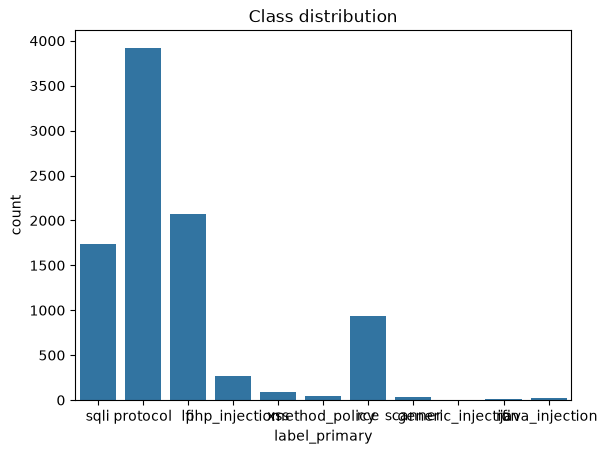

In [39]:


sns.countplot(x=y_train)
plt.title("Class distribution")
plt.show()